# NumPy

Nhóm lập trình có điểm ba môn của một lớp. Điểm Toán và điểm Tin có cùng thang 0–10 nhưng độ phân tán khác nhau; một điểm cao hơn trung bình một đơn vị chưa chắc nổi bật như nhau ở hai môn. Muốn so theo độ lệch chuẩn, ta cần tính trung bình và độ lệch chuẩn riêng cho mỗi cột, rồi biến đổi từng ô. Câu hỏi của bài là: **làm sao tính trên cả bảng mà vẫn biết mỗi kết quả ứng với ai, với môn nào?**

NumPy giải quyết công việc đó bằng mảng có **shape**, phép gộp theo **axis**, và **broadcasting**. Một ảnh có thể được biểu diễn bằng mảng $(H, W, 3)$; một batch ảnh cho mạng neural có thể dùng quy ước $(N, 3, H, W)$. Quy ước trục phải được đọc từ dữ liệu và thư viện, không đoán theo vẻ ngoài. Kiến thức này sẽ dùng lại khi học tensor trong PyTorch; khi ấy ta còn học gradient tự động và thiết bị tính toán.

> **Sau bài này, có thể**
>
> - Viết lại vòng lặp trên từng phần tử thành phép toán trên cả mảng, và đo được chênh lệch tốc độ.
> - Đoán trước shape của kết quả khi gộp theo axis và khi broadcasting, kể cả với mảng 3 chiều.
> - Phân biệt view và copy, biết khi nào sửa một lát cắt làm đổi mảng gốc.
> - Nhận ra và tránh lỗi $(n,)$ trừ $(n, 1)$, lỗi tràn số với `uint8`, lỗi shape âm thầm.

## Mảng và shape

Mảng NumPy (`ndarray`) gồm một vùng dữ liệu, một kiểu phần tử (`dtype`) chung cho mọi ô, và cách đọc vùng dữ liệu ấy (`shape`, `strides`). Nhờ mọi ô cùng kiểu số, NumPy duyệt mảng bằng code đã biên dịch thay cho từng câu lệnh Python. Một mảng mới tạo thường nằm liền trong bộ nhớ; một lát cắt thì có thể dùng chung dữ liệu với mảng gốc và nhảy cách quãng.



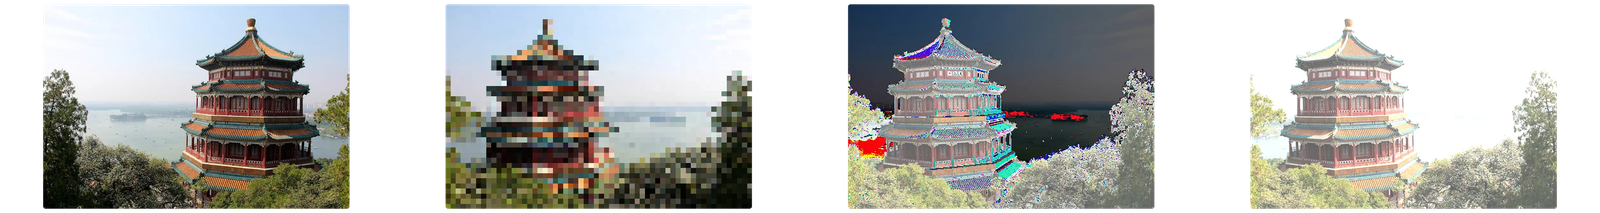

`shape` trả lời “có bao nhiêu phần tử trên mỗi trục”, `ndim` là số trục, `size` là tích các độ dài trục. Với bảng hai hàng và ba cột, phần tử `a[1, 2]` nằm ở hàng thứ hai, cột thứ ba:

In [ ]:
import numpy as np

a = np.array([[1, 2, 3], [4, 5, 6]], dtype=np.int64)
print(a.shape, a.ndim, a.size, a.dtype)
print(np.zeros((2, 3)).dtype, np.arange(6).reshape(2, 3).tolist())
print(np.linspace(0, 1, 5))
print(np.arange(12).reshape(3, -1).shape)    # -1: NumPy tự tính trục còn lại

(2, 3) 2 6 int64
float64 [[0, 1, 2], [3, 4, 5]]
[0.   0.25 0.5  0.75 1.  ]
(3, 4)


`reshape` giữ cùng dãy giá trị, đọc 12 số thành $3 \times 4$ hay $2 \times 6$, miễn tích các trục bằng 12. Chỉ một trục được viết `-1` để tự suy ra. Khi bố trí bộ nhớ cho phép, kết quả là view; với một số mảng đã chuyển vị hoặc cắt, NumPy phải tạo bản sao. Ta kiểm bằng `np.shares_memory` khi việc dùng chung dữ liệu có ý nghĩa với chương trình.



Kiểu dữ liệu là chỗ NumPy khác Python nhiều nhất. `int` Python có độ chính xác tùy ý, nhưng số nguyên NumPy có độ rộng cố định. Phép toán trên mảng nguyên có thể quay vòng khi vượt miền biểu diễn, không nhất thiết báo lỗi:

In [ ]:
big = np.array([2**62], dtype=np.int64)
print(big * 4, big.dtype)

pixels = np.array([200, 100], dtype=np.uint8)   # ảnh thường lưu bằng uint8, giá trị 0..255
print(pixels + 100)

x = np.array([1, 2, 3])
x[0] = 2.7                                       # gán số thực vào mảng nguyên: bị cắt
print(x)

[0] int64
[ 44 200]
[2 2 3]


$2^{62} \cdot 4 = 2^{64}$ vượt `int64` và quay vòng về 0 trong phép toán này. Điểm ảnh $200 + 100 = 300$ vượt 255 và thành $300 - 256 = 44$. Đổi sang `float32` trước khi xử lý rồi kẹp về miền hợp lệ bằng `np.clip` sẽ tránh phép cộng `uint8` bị quay vòng. Dòng cuối cho thấy gán số thực vào mảng nguyên làm mất phần lẻ.



Một phần tử `float32` dùng 4 byte, `float64` dùng 8 byte. `float64` chính xác hơn nhưng tốn gấp đôi bộ nhớ; nhiều mô hình học sâu dùng `float32` trên cả CPU lẫn GPU để tiết kiệm bộ nhớ và chạy nhanh hơn. Nhãn phân loại, chỉ số và dữ liệu ảnh lưu trữ vẫn có thể cần kiểu nguyên. Chọn dtype theo vai trò của dữ liệu, không đổi mọi mảng thành số thực.

**Hỏi nhanh.** `np.array([250, 10], dtype=np.uint8) + 10` cho ra gì?

- A. `[260, 20]`
- B. `[4, 20]`
- C. `[255, 20]`
- D. Báo lỗi tràn số

<details><summary>Đáp án</summary>

B. `[4, 20]`

`uint8` chỉ chứa được các số từ 0 đến 255. $250 + 10 = 260$ vượt quá, nên quay vòng về $260 - 256 = 4$, và NumPy không báo gì cả. Nhiều bạn tưởng giá trị sẽ dừng ở 255, nhưng NumPy không làm thế.

</details>

## Tính trên cả mảng

Phép toán số học, so sánh và các hàm như `np.exp`, `np.sqrt`, `np.log` áp dụng lên từng phần tử của mảng mà không cần vòng lặp. Cách viết này gọi là vector hóa (vectorization):

In [ ]:
z = np.array([-2.0, 0.0, 1.0, 3.0])
print(1 / (1 + np.exp(-z)))                      # sigmoid của bài 2.3, cho cả mảng
print(z > 0, (z > 0).sum(), (z > 0).mean())
print(np.where(z > 0, z, 0.0))                   # ReLU: giữ số dương, số âm thành 0
print(np.clip(z, -1, 1), z.max(), z.argmax())

[0.11920292 0.5        0.73105858 0.95257413]
[False False  True  True] 2 0.5
[0. 0. 1. 3.]
[-1.  0.  1.  1.] 3.0 3


So sánh cho ra mảng `bool`; cộng mảng `bool` thì `True` tính là 1, nên `(z > 0).sum()` đếm số phần tử dương và `(z > 0).mean()` là tỉ lệ của chúng. Đây là cách tính accuracy: `(pred == y).mean()`.

**Hỏi nhanh.** Với `z = np.array([-2.0, 0.0, 1.0, 3.0])`, dòng `if z > 0: print("dương")` làm gì?

- A. In “dương”, vì `z` có ít nhất một phần tử dương
- B. Không in gì, vì không phải mọi phần tử đều dương
- C. Báo `ValueError`, vì `if` không tự chọn `any` hay `all`
- D. In “dương” hai lần, mỗi phần tử dương một lần

<details><summary>Đáp án</summary>

C. Báo `ValueError`, vì `if` không tự chọn `any` hay `all`

`z > 0` là một mảng bốn giá trị `bool`, còn `if` chỉ nhận đúng một giá trị. NumPy không đoán thay ta, nên phải nói rõ: `(z > 0).any()` nếu muốn “có ít nhất một phần tử dương”, `(z > 0).all()` nếu muốn “mọi phần tử đều dương”.

</details>

Trong đoạn sigmoid, mỗi giá trị $z$ được đổi thành $1/(1+e^{-z})$, nằm trong $(0,1)$. Chưa cần hiểu mô hình dùng nó; ta chỉ cần nhận ra cùng một công thức được áp vào từng phần tử. Đo thử cho 200 000 số, kiểm kết quả bằng `allclose` trước rồi mới lưu thời gian của hai cách:

In [ ]:
import math
from timeit import repeat

rng = np.random.default_rng(0)
z = rng.normal(size=200_000)
zs = z.tolist()

def sigmoid_loop(values):
    return [1 / (1 + math.exp(-value)) for value in values]

def sigmoid_numpy(values):
    return 1 / (1 + np.exp(-values))

p_loop = sigmoid_loop(zs)
p_vec = sigmoid_numpy(z)
assert np.allclose(p_loop, p_vec)
t_loop = min(repeat(lambda: sigmoid_loop(zs), repeat=5, number=3)) / 3
t_vec = min(repeat(lambda: sigmoid_numpy(z), repeat=5, number=3)) / 3
print(np.allclose(p_loop, p_vec), p_vec.shape)
print("NumPy nhanh hơn vòng lặp:", t_vec < t_loop)

True (200000,)
NumPy nhanh hơn vòng lặp: True


Hai cách cho cùng 200 000 đầu ra (sai khác chỉ ở chữ số cuối), và NumPy nhanh hơn. `t_loop`, `t_vec` giữ số giây của một lượt trên máy đang dùng; bước đổi sang list không được tính vào. Hình dưới là một lần đo như vậy. Tỉ lệ nhanh chậm phụ thuộc công thức và kích thước mảng, nên khi cần con số thì đo trên chính công việc của mình.



## Chỉ số và lát cắt

Mảng nhiều chiều dùng một cặp ngoặc với các chỉ số ngăn bởi dấu phẩy: `a[i, j]`, không phải `a[i][j]` (cách sau vẫn chạy nhưng chậm hơn và dễ sai với lát cắt). Mỗi trục nhận một chỉ số, một lát cắt `start:stop:step`, một list chỉ số, hoặc một mặt nạ `bool`:

In [ ]:
a = np.arange(12).reshape(3, 4)
print(a)
print(a[1, 2], a[:, 0], a[-1, ::2])
print(a[[0, 2]].shape, a[a % 5 == 0])

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
6 [0 4 8] [ 8 10]
(2, 4) [ 0  5 10]


`a[:, 0]` là cột đầu, $(3,)$. `a[[0, 2]]` lấy hàng 0 và hàng 2 (fancy indexing). `a[a % 5 == 0]` lấy mọi phần tử chia hết cho 5 và trả về mảng một chiều.



Có một khác biệt quan trọng với list. Lát cắt của list Python tạo bản sao; lát cắt của mảng NumPy là một **view**: một cách nhìn khác vào cùng vùng nhớ. Sửa view thì mảng gốc đổi theo:

In [ ]:
a = np.arange(6)
s = a[1:4]                  # view
s[0] = 100
print(a)

f = a[[1, 2, 3]]            # fancy indexing: luôn là bản sao
f[0] = -1
print(a, np.shares_memory(a, s), np.shares_memory(a, f))

[  0 100   2   3   4   5]
[  0 100   2   3   4   5] True False


Quy tắc: lát cắt bằng `start:stop:step` cho view; chỉ số bằng list hay mặt nạ `bool` cho bản sao. View giúp NumPy không tốn bộ nhớ khi cắt mảng lớn, nhưng nếu định sửa lát cắt mà không muốn đụng tới gốc thì phải gọi `.copy()`.



Quy tắc “fancy indexing tạo bản sao” nói về **đọc** ra một mảng mới. Lệnh gán trực tiếp `a[a > 5] = 0` vẫn sửa những ô tương ứng của `a`; nó không giống `b = a[a > 5]` rồi sửa `b`. Cần tách bạch việc đọc ra một mảng mới với việc gán thẳng vào mảng cũ.

**Hỏi nhanh.** Chạy `a = np.zeros(5)`, `b = a[2:]`, `b += 1`. Lúc này `a` là gì?

- A. `[0, 0, 0, 0, 0]`
- B. `[1, 1, 1, 1, 1]`
- C. `[0, 0, 1]`
- D. `[0, 0, 1, 1, 1]`

<details><summary>Đáp án</summary>

D. `[0, 0, 1, 1, 1]`

Lát cắt `a[2:]` của NumPy là một view: `b` nhìn thẳng vào ba ô cuối của `a`, nên `b += 1` sửa luôn trên `a`. Với list Python thì khác, lát cắt là bản sao và `a` sẽ không đổi.

</details>

## axis

Giờ đến bảng điểm: 5 học sinh, 3 môn. Mỗi hàng là một học sinh, mỗi cột là một môn. Ý nghĩa của từng trục do ta quy ước; trong học máy, quy ước gần như luôn là **trục 0 là các mẫu**.

In [ ]:
scores = np.array([[9, 8, 7],
                   [5, 6, 4],
                   [4, 4, 5],
                   [9, 8, 10],
                   [7, 8, 10]], dtype=float)       # (5 học sinh, 3 môn)
print(scores.mean(axis=0))                         # trung bình từng môn
print(scores.mean(axis=1).round(2))                # trung bình từng học sinh
print(scores.argmax(axis=1), scores.max())

[6.8 6.8 7.2]
[8.   5.   4.33 9.   8.33]
[0 1 2 2 2] 10.0


Cách nhớ: **trục nào được ghi trong `axis` thì trục đó biến mất**. `scores` có shape $(5, 3)$; `mean(axis=0)` gộp theo trục 0 (gộp 5 học sinh lại) nên còn $(3,)$, một số cho mỗi môn. `mean(axis=1)` gộp 3 môn nên còn $(5,)$, một số cho mỗi học sinh. Không ghi `axis` thì gộp tất cả thành một số.



Quy tắc giữ nguyên với mảng nhiều chiều hơn. Một batch 100 ảnh xám $28 \times 28$ có shape $(100, 28, 28)$:

In [ ]:
imgs = rng.random((100, 28, 28))
print(imgs.mean(axis=0).shape)                     # ảnh trung bình
print(imgs.mean(axis=(1, 2)).shape)                # độ sáng trung bình của từng ảnh
print(imgs.mean(axis=(1, 2), keepdims=True).shape)

(28, 28)
(100,)
(100, 1, 1)


`keepdims=True` giữ lại trục bị gộp với độ dài 1 thay vì xóa nó. Mục sau sẽ cho thấy vì sao điều đó hữu ích.

Với ảnh thật, hai phép gộp này có nghĩa rất cụ thể. scikit-learn kèm sẵn 1797 ảnh chữ số viết tay $8 \times 8$:



Muốn ghép dữ liệu, cũng phải nói rõ ý nghĩa trục. `concatenate` nối dọc một trục đã có; `stack` tạo một trục mới. Ví dụ gom hai phần của cùng lớp khác với xếp hai bảng thành hai buổi đo:

In [ ]:
joined = np.concatenate([scores[:2], scores[2:]], axis=0)
two_sessions = np.stack([scores, scores], axis=0)
print(joined.shape, np.array_equal(joined, scores))
print(two_sessions.shape)    # (buổi, học sinh, môn)

(5, 3) True
(2, 5, 3)


Shape `(2, 5, 3)` không chỉ là “thêm một số 2”; nó có thêm trục buổi đo. Nếu ghép sai axis, chương trình vẫn có thể chạy nhưng mô hình sẽ đọc nhầm đâu là mẫu và đâu là đặc trưng.



**Hỏi nhanh.** `X` có shape $(32, 3, 64, 64)$, tức là 32 ảnh màu, mỗi ảnh 3 kênh, $64 \times 64$ điểm ảnh. `X.mean(axis=(0, 2, 3))` có shape gì?

- A. $(3,)$
- B. $(32,)$
- C. $(64, 64)$
- D. $(32, 3)$

<details><summary>Đáp án</summary>

A. $(3,)$

Các trục 0, 2, 3 bị gộp nên biến mất, chỉ còn trục kênh. Kết quả là ba số, mỗi số là độ sáng trung bình của một kênh màu, tính trên mọi ảnh và mọi điểm ảnh.

</details>

## Broadcasting

Chuẩn hóa từng môn: lấy `scores` $(5, 3)$ trừ trung bình từng môn $(3,)$. Hai mảng khác shape, nhưng phép trừ vẫn chạy:

In [ ]:
mu = scores.mean(axis=0)
sigma = scores.std(axis=0)
sigma_safe = np.where(sigma == 0, 1.0, sigma)
Z = (scores - mu) / sigma_safe
print(Z.shape, Z.mean(axis=0).round(6), Z.std(axis=0))

(5, 3) [ 0.  0. -0.] [1. 1. 1.]


Trung bình một cột là $\mu_j = \frac{1}{5}\sum_i x_{ij}$, độ lệch chuẩn đang dùng là $\sigma_j = \sqrt{\frac{1}{5}\sum_i (x_{ij}-\mu_j)^2}$. NumPy mặc định `std(ddof=0)`, đúng mẫu số 5 ở đây. Giá trị mới $z_{ij}=(x_{ij}-\mu_j)/\sigma_j$ không còn đơn vị điểm; nó cho biết một ô cách trung bình bao nhiêu độ lệch chuẩn.

Đọc output: ba trung bình gần 0 và ba độ lệch chuẩn bằng 1. `-0.` chỉ là một số âm rất nhỏ đã làm tròn về 0. Nếu một môn có mọi điểm giống nhau thì $\sigma_j=0$; `sigma_safe` thay mẫu số bằng 1 và cột ấy thành toàn 0. Khi dùng bước biến đổi này cho mô hình, `mu` và `sigma_safe` được tính trên tập train rồi dùng lại nguyên vẹn cho validation và test (bài 1.4).

NumPy đã ghép từng phần tử của `mu` $(3,)$ với cả cột tương ứng của bảng $(5,3)$. Cơ chế này gọi là broadcasting: mảng nhỏ được “kéo dãn” mà không thật sự sao chép ra nhiều lần, dù **kết quả** của phép tính vẫn chiếm đủ bộ nhớ. Có hai quy tắc:

1. Xếp shape của hai mảng thẳng hàng **từ bên phải**. Mảng nào ít trục hơn thì coi như có thêm các trục độ dài 1 ở bên trái.
2. Ở mỗi trục, hai độ dài phải bằng nhau, hoặc một trong hai bằng 1. Trục độ dài 1 được kéo dãn cho khớp trục kia.

| `A` | `B` | Kết quả | Vì sao |
|---|---|---|---|
| $(5, 3)$ | $(3,)$ | $(5, 3)$ | $(3,)$ thành $(1, 3)$, kéo dãn trục 0 |
| $(5, 3)$ | $(5, 1)$ | $(5, 3)$ | Kéo dãn trục 1 của `B` |
| $(4, 1)$ | $(3,)$ | $(4, 3)$ | Cả hai cùng được kéo dãn |
| $(5, 3)$ | $(5,)$ | Lỗi | $(5,)$ thành $(1, 5)$; trục cuối $3 \ne 5$ |



Dòng cuối của bảng là lỗi thường gặp khi muốn trừ trung bình **của từng học sinh**: `scores.mean(axis=1)` có shape $(5,)$, xếp thẳng từ phải với $(5, 3)$ thì không khớp. Đây là lúc dùng `keepdims`:

In [ ]:
row_mean = scores.mean(axis=1)
try:
    scores - row_mean
except ValueError as e:
    print("ValueError:", e)
print((scores - scores.mean(axis=1, keepdims=True)).shape)

ValueError: operands could not be broadcast together with shapes (5,3) (5,) 
(5, 3)


Với `keepdims=True`, trung bình có shape $(5, 1)$ và kéo dãn đúng theo trục môn học.

Broadcasting còn thay được cả vòng lặp lồng nhau. Tính khoảng cách giữa mọi cặp điểm của hai tập $A$ ($n$ điểm) và $B$ ($m$ điểm) trong $d$ chiều, việc mà bài 2.4 (k-nearest neighbors) cần, bằng cách chèn thêm trục độ dài 1:

In [ ]:
A = np.array([[0.0, 0.0], [3.0, 4.0]])
B = np.array([[0.0, 4.0], [3.0, 0.0]])
diff = A[:, None, :] - B[None, :, :]  # (2, 1, 2) - (1, 2, 2) -> (2, 2, 2)
D = np.sqrt((diff ** 2).sum(axis=-1))
print(diff.shape, D.shape)
print(D)
print(diff.nbytes)

(2, 2, 2) (2, 2)
[[4. 3.]
 [3. 4.]]
64


`None` (hoặc `np.newaxis`) chèn một trục độ dài 1. Trục cuối chứa tọa độ; gộp nó để lấy một khoảng cách cho mỗi cặp, shape `(n, m)`. Cặp đầu là từ $(0,0)$ đến $(0,4)$, khoảng cách bằng 4; cặp hàng 1, cột 0 là từ $(3,4)$ đến $(0,4)$, khoảng cách bằng 3. Bốn ô đều tính tay được, nên ví dụ nhỏ này là phép thử cho code trước khi chạy trên dữ liệu thật.



Mảng `diff` nhỏ dùng $2\cdot2\cdot2\cdot8=64$ byte. Với $n=500$, $m=300$, $d=64$, riêng mảng ấy dùng $76\,800\,000$ byte, tức 76.8 MB thập phân. Với $n=m=10\,000$, số byte lên $51.2$ GB. Đó chưa gồm `diff ** 2`, kết quả và mảng đầu vào. Ước lượng **mảng trung gian** trước khi chạy lớn; bài k-nearest neighbors sẽ có cách chia khối hoặc công thức tránh lưu cả trục tọa độ.

**Hỏi nhanh.** `A` có shape $(8, 1, 6)$, `B` có shape $(7, 1)$. `(A + B).shape` là gì?

- A. Báo lỗi, vì hai mảng khác số trục
- B. $(8, 7, 1)$
- C. $(8, 1, 6)$
- D. $(8, 7, 6)$

<details><summary>Đáp án</summary>

D. $(8, 7, 6)$

Xếp hai shape thẳng từ bên phải. `B` thiếu một trục thì coi như có thêm trục dài 1 ở bên trái, thành $(1, 7, 1)$. Ở mỗi trục, bên nào dài 1 thì được kéo dãn theo bên kia: trục cuối ra 6, trục giữa ra 7, trục đầu ra 8. Hai mảng khác số trục vẫn cộng được.

</details>

## $(n,)$ và $(n, 1)$

Hai shape này trông giống nhau và in ra gần giống nhau, nhưng là hai thứ khác hẳn. $(n,)$ là vector một trục. $(n, 1)$ là ma trận $n$ hàng, một cột. Trộn chúng với nhau là lỗi âm thầm nguy hiểm nhất của NumPy, vì broadcasting biến nó thành một phép tính hợp lệ nhưng sai:

In [ ]:
y = np.array([1.0, 2.0, 3.0])                      # (3,): nhãn thật
y_hat = np.array([[1.0], [2.0], [3.0]])            # (3, 1): dự đoán, đúng hoàn toàn
print((y_hat - y).shape)
print("MSE sai:", np.mean((y_hat - y) ** 2), "  MSE đúng:", np.mean((y_hat.ravel() - y) ** 2))

(3, 3)
MSE sai: 1.3333333333333333   MSE đúng: 0.0


Dự đoán đúng hoàn toàn mà MSE ra $1.33$ thay vì $0$. Phép trừ $(3, 1) - (3,)$ broadcast thành ma trận $3 \times 3$ chứa mọi hiệu $\hat y_i - y_j$, rồi `np.mean` lấy trung bình cả 9 số. Không có lỗi nào được báo. Với $n = 10^5$ mẫu, ma trận này có $10^{10}$ phần tử, và may mắn duy nhất là lúc đó notebook sẽ hết bộ nhớ.



Lỗi này hay xuất hiện khi mô hình trả dự đoán dạng $(n,1)$, ví dụ đầu ra của một mạng neural một neuron. Cách phòng là đặt `assert` ở hàm tính loss, và chỉ dùng `.ravel()` hoặc `.reshape(-1)` khi biết chắc mỗi mẫu cần một đầu ra. Với đầu ra nhiều lớp, làm phẳng có thể phá ý nghĩa trục thay vì sửa lỗi:

In [ ]:
def mse(y_hat, y):
    assert y_hat.shape == y.shape, (y_hat.shape, y.shape)
    return np.mean((y_hat - y) ** 2)

try:
    mse(y_hat, y)
except AssertionError as e:
    print("AssertionError:", e)

AssertionError: ((3, 1), (3,))


**Hỏi nhanh.** `y_hat` có shape $(1000, 1)$, còn `y` có shape $(1000,)$. Ta tính `np.mean((y_hat - y) ** 2)`. Kết quả ra sao?

- A. Ra một con số sai, và không báo lỗi gì
- B. Báo lỗi, vì hai shape khác nhau
- C. Ra đúng MSE, vì NumPy tự khớp hai shape
- D. Chỉ tính trên mẫu đầu tiên của mỗi mảng

<details><summary>Đáp án</summary>

A. Ra một con số sai, và không báo lỗi gì

Broadcasting biến phép trừ $(1000, 1) - (1000,)$ thành một ma trận $(1000, 1000)$ chứa mọi hiệu $\hat y_i - y_j$, rồi lấy trung bình cả triệu số ấy. NumPy có tự khớp hai shape thật, nhưng khớp sai ý ta. Phải đưa `y_hat` về $(1000,)$ bằng `.ravel()` rồi mới trừ.

</details>

## Đại số tuyến tính và số ngẫu nhiên

Phép nhân ma trận dùng `@`. Phép `*` là nhân từng phần tử, không phải nhân ma trận:

In [ ]:
M = np.array([[2.0, 1.0], [1.0, 3.0]])
v = np.array([1.0, 2.0])
print(M @ v, M * v)
print(M.T @ M)
print(np.linalg.solve(M, v), np.linalg.norm(v))

[4. 7.] [[2. 2.]
 [1. 6.]]
[[ 5.  5.]
 [ 5. 10.]]
[0.2 0.6] 2.23606797749979


`M @ v` với $M$ $(2,2)$ và $v$ $(2,)$ cho $(2,)$. Hàng đầu tính $2\cdot1+1\cdot2=4$; hàng sau tính $1\cdot1+3\cdot2=7$. Với hai ma trận, quy tắc là $(n,k)@(k,m)\to(n,m)$: số cột bên trái phải bằng số hàng bên phải. `M * v` lại nhân cột đầu với 1, cột sau với 2 theo broadcasting.



`np.linalg.solve(M, v)` giải $M\mathbf{x}=\mathbf{v}$ khi $M$ vuông và khả nghịch. Với kết quả $(0.2,0.6)$, kiểm tay: $2\cdot0.2+0.6=1$ và $0.2+3\cdot0.6=2$. Khi mục đích là giải hệ, dùng `solve` trực tiếp thay vì tính nghịch đảo rồi nhân. Hệ suy biến cần phương pháp khác như `lstsq`; ta sẽ học khi làm linear regression.

**Hỏi nhanh.** Ma trận $A$ có 3 hàng, 4 cột. Với mọi $\mathbf{x} = (x_0, x_1, x_2, x_3)$, ta có $A\mathbf{x} = (x_2 - x_3,\ x_3,\ x_0 + 2x_1)$. Hàng đầu của $A$ là gì?

- A. `[1, -1, 0, 0]`
- B. `[0, 0, 1, 0]`
- C. `[0, 0, 1, -1]`
- D. `[1, 2, 0, 0]`

<details><summary>Đáp án</summary>

C. `[0, 0, 1, -1]`

Mỗi phần tử của $A\mathbf{x}$ là tích vô hướng của một hàng với $\mathbf{x}$. Vì vậy hàng thứ $i$ chính là dãy hệ số của $x_0, x_1, x_2, x_3$ trong phần tử thứ $i$. Phần tử đầu là $x_2 - x_3$, nên hàng đầu là `[0, 0, 1, -1]`. Làm tương tự, hai hàng sau là `[0, 0, 0, 1]` và `[1, 2, 0, 0]`.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 1 · Problem 3.1](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-1-problems.pdf#page=7)

</details>

Số ngẫu nhiên dùng một bộ sinh có seed, để chạy lại cho đúng kết quả cũ:

In [ ]:
rng = np.random.default_rng(42)
print(rng.integers(0, 10, size=5), rng.normal(size=2).round(3))
print(rng.permutation(5), rng.choice(["A", "B", "C"], size=4))
rng2 = np.random.default_rng(42)
print(rng2.integers(0, 10, size=5))                # cùng seed: cùng dãy số

[0 7 6 4 4] [ 0.941 -1.951]
[3 4 1 0 2] ['C' 'C' 'C' 'B']
[0 7 6 4 4]


Hai bộ sinh cùng seed, gọi theo cùng trình tự, cho cùng dãy số. Mỗi lần gọi trên `rng` làm trạng thái của nó tiến tiếp, nên seed không có nghĩa “lần gọi nào cũng ra cùng một mảng”. Mỗi phần cần ngẫu nhiên nên nhận một `rng` hoặc seed rõ ràng. Cách cũ `np.random.seed(...)` dùng trạng thái toàn cục, dễ bị một đoạn code khác chen vào làm lệch.



**Hỏi nhanh.** ```py
rng = np.random.default_rng(42)
a = rng.integers(0, 10, size=5)
b = rng.integers(0, 10, size=5)
```
`a` có bằng `b` không? Chạy lại cả đoạn thì có ra đúng các số cũ không?

- A. `a` bằng `b`, và chạy lại ra đúng số cũ
- B. `a` khác `b`, và chạy lại ra đúng số cũ
- C. `a` bằng `b`, và chạy lại ra số mới
- D. `a` khác `b`, và chạy lại ra số mới

<details><summary>Đáp án</summary>

B. `a` khác `b`, và chạy lại ra đúng số cũ

Seed cố định cả một **dãy** số, mỗi lần gọi lấy tiếp phần sau của dãy. Vì thế `b` là đoạn nối tiếp sau `a`, không lặp lại `a`: ở đây `a` là `[0 7 6 4 4]` còn `b` là `[8 0 6 2 0]`. Chạy lại cả đoạn thì `rng` được tạo lại với cùng seed, nên cả dãy lặp lại y như cũ.

</details>

## Sắp xếp, đếm, cộng dồn và lưu mảng

Sắp xếp, đếm, mảng cộng dồn và tìm nhị phân đều có sẵn trong NumPy. Học máy dùng chúng để lấy top-k lớp, đếm mẫu mỗi nhãn, chia điểm thành khoảng.

In [ ]:
scores = np.array([7.5, 9.0, 4.0, 9.0, 6.5])
order = np.argsort(-scores, kind="stable")       # chỉ số theo điểm giảm dần
print(order, scores[order])
top2 = np.argpartition(-scores, 2)[:2]           # hai chỉ số điểm cao nhất, không sắp cả mảng
print(np.sort(top2))
labels = np.array([2, 0, 2, 1, 2, 0])
print(np.unique(labels, return_counts=True))
print(np.bincount(labels, minlength=4))
print(np.cumsum([3, 1, 4, 1, 5]))
edges = np.array([5.0, 6.5, 8.0])                # ngưỡng điểm: dưới 5, 5–6.5, 6.5–8, từ 8
print(np.searchsorted(edges, [4.0, 6.5, 9.0], side="right"))

[1 3 0 4 2] [9.  9.  7.5 6.5 4. ]
[1 3]
(array([0, 1, 2]), array([2, 1, 3]))
[2 1 3 0]
[ 3  4  8  9 14]
[0 2 3]


`argsort` trả về **chỉ số**. Sắp `-scores` để được thứ tự giảm dần; `kind="stable"` giữ hai điểm 9.0 theo thứ tự xuất hiện. `argpartition` giống `nth_element` của C++: đưa $k$ chỉ số lớn nhất lên đầu trong thời gian tuyến tính nhưng không sắp chúng.



`unique` trả về các nhãn và số lần xuất hiện. `bincount` đếm số nguyên không âm: ô $i$ là số lần gặp $i$; `minlength=4` giữ cả ô của nhãn 3 không xuất hiện. `cumsum` là prefix sum. `searchsorted` tìm nhị phân trên mảng đã sắp, `side="right"` giống `upper_bound`: điểm 6.5 rơi vào khoảng 2, từ 6.5 tới dưới 8.

**Hỏi nhanh.** `np.argsort(np.array([30, 10, 20]))` in ra gì?

- A. `[2 0 1]`
- B. `[1 2 0]`
- C. `[10 20 30]`
- D. `[0 1 2]`

<details><summary>Đáp án</summary>

B. `[1 2 0]`

Nhỏ nhất là 10 ở chỉ số 1, rồi 20 ở chỉ số 2, rồi 30 ở chỉ số 0. `[2 0 1]` là **thứ hạng** của từng phần tử; muốn có thứ hạng thì gọi `argsort` hai lần.

</details>

Đặc trưng hay embedding tính lâu thì lưu lại bằng định dạng của NumPy; lần sau nạp ngay, giữ nguyên `shape` và `dtype`:

In [ ]:
from pathlib import Path
from tempfile import TemporaryDirectory

with TemporaryDirectory() as directory:
    path = Path(directory) / "features.npz"
    np.savez_compressed(path, X=np.arange(6, dtype=np.float32).reshape(2, 3), y=np.array([0, 1]))
    with np.load(path) as data:
        print(data.files, data["X"].shape, data["X"].dtype, data["y"])

['X', 'y'] (2, 3) float32 [0 1]


`np.save` ghi một mảng ra `.npy`; `np.savez_compressed` gom nhiều mảng có tên vào một tệp `.npz`. CSV làm mất `dtype` và chậm với mảng lớn. Trên Kaggle, tệp ghi vào `/kaggle/working` còn lại sau khi lưu phiên bản.

## Ví dụ tính tay

Đoán shape và giá trị trước khi chạy:

1. `np.arange(3).reshape(3, 1) + np.arange(3)`. Shape $(3, 1) + (3,) \to (3, 3)$; phần tử $(i, j)$ bằng $i + j$, nên kết quả là `[[0, 1, 2], [1, 2, 3], [2, 3, 4]]`.
2. `np.ones((2, 3)).sum(axis=0)`. Trục 0 biến mất: $(3,)$, giá trị `[2, 2, 2]`.
3. `np.ones((4, 5, 6)).sum(axis=(0, 2), keepdims=True).shape`. Trục 0 và 2 thành độ dài 1: $(1, 5, 1)$; mỗi phần tử bằng $4 \cdot 6 = 24$.
4. `np.array([[1, 2], [3, 4]]) @ np.array([1, 1])`. $(2, 2) @ (2,) \to (2,)$: tổng từng hàng, `[3, 7]`.
5. `(np.array([1, 5, 3]) > 2).mean()`. Mặt nạ `[False, True, True]`, trung bình là $2/3 \approx 0.667$.

## Bẫy cài đặt

**`if` trên một mảng.** `if a > 0:` với `a` có nhiều phần tử báo `ValueError: The truth value of an array with more than one element is ambiguous`. Phải nói rõ ý cần kiểm: `(a > 0).all()` hay `(a > 0).any()`. Ghép hai điều kiện phần tử dùng `(a > 0) & (a < 5)`, có ngoặc cho từng điều kiện.

**Tên `vectorize` gây hiểu nhầm.** `np.vectorize` tiện để gọi một hàm Python trên nhiều phần tử, nhưng về cơ bản vẫn là vòng lặp; nó không tự biến hàm đó thành phép toán số đã biên dịch. Muốn tăng tốc, tìm ufunc, phép gộp, broadcasting hoặc thuật toán phù hợp rồi đo.

**Sửa view tưởng là bản sao.** `b = a[:, 0]; b -= b.mean()` làm đổi cột đầu của `a`. Gọi `.copy()` nếu không muốn đụng tới gốc.

**Tràn số với kiểu nguyên.** Ảnh `uint8` cộng trừ dễ quay vòng; đổi sang `float32` trước khi tính, và chia cho 255 nếu cần giá trị trong $[0, 1]$.

**$(n,)$ lẫn với $(n, 1)$.** `assert y_hat.shape == y.shape` ở mọi hàm loss và metric tự viết.

**Mảng trung gian quá lớn.** Broadcasting $(n, 1, d) - (1, m, d)$ tạo mảng $n \cdot m \cdot d$ phần tử. Ước lượng bộ nhớ trước: mỗi số `float64` tốn 8 byte.

## Khi đi thi

- **In shape ở mọi bước** khi viết code mới: `print(X.shape, y.shape)`. Phần lớn lỗi ở các chương sau là lỗi shape.
- **Tìm phép toán mảng tương đương** khi tính cùng công thức trên nhiều số; đối chiếu một ví dụ nhỏ bằng vòng lặp trước.
- **Kiểm tra `dtype`** khi đọc ảnh hay dữ liệu: `uint8`, `int64`, `float32`, `float64` cho kết quả khác nhau.
- **Một `rng` có seed** cho toàn bộ notebook, truyền vào các hàm cần ngẫu nhiên.
- **Ước lượng bộ nhớ** của đầu vào, kết quả và mảng trung gian. RAM khả dụng phải đọc từ môi trường cụ thể; không dựa vào một con số cố định cho mọi tài khoản hay kỳ thi.

## Tóm tắt

- Mảng NumPy có `shape`, `dtype` và cách đọc bộ nhớ; view không nhất thiết liền bộ nhớ. Số nguyên độ rộng cố định có thể tràn.
- Phép toán, so sánh và hàm toán học áp dụng lên cả mảng. Kiểm đúng rồi đo tốc độ trên công việc cụ thể.
- Lát cắt `start:stop` là view; list chỉ số và mặt nạ `bool` cho bản sao.
- Gộp theo `axis` làm trục đó biến mất; `keepdims=True` giữ nó lại với độ dài 1.
- Broadcasting xếp shape từ phải, kéo dãn trục độ dài 1. Cẩn thận với $(n,)$ và $(n, 1)$.
- `@` là nhân ma trận, `*` là nhân từng phần tử; số ngẫu nhiên qua `np.random.default_rng(seed)`.

## Kiểm tra cuối bài

Mười câu dưới đây bao quát cả bài. Làm hết rồi xem điểm; câu nào sai thì đọc lại mục tương ứng.

**Câu 1.** `np.arange(24).reshape(2, 3, -1).shape` là gì?

- A. $(2, 3, 1)$
- B. $(2, 3, 24)$
- C. $(2, 3, 4)$
- D. Báo lỗi

<details><summary>Đáp án</summary>

C. $(2, 3, 4)$

`-1` nghĩa là “NumPy tự tính trục này giúp tôi”. Tích các trục phải bằng 24, nên trục ấy dài $24 / (2 \cdot 3) = 4$. `-1` không có nghĩa là dài 1, cũng không giữ nguyên 24.

</details>
**Câu 2.** Có hai mảng NumPy `pred = [1, 0, 1, 1, 0]` và `y = [1, 1, 1, 0, 0]`. `(pred == y).mean()` bằng bao nhiêu?

- A. 1
- B. 0.6
- C. 0.4
- D. 3

<details><summary>Đáp án</summary>

B. 0.6

So từng cặp ta được `[True, False, True, False, True]`. Khi lấy trung bình, `True` tính là 1, `False` tính là 0. Đúng 3 trên 5 mẫu nên kết quả là $3/5 = 0.6$, chính là accuracy. 0.4 là tỉ lệ đoán sai, còn 3 là kết quả của `sum`.

</details>
**Câu 3.** Chạy `a = np.arange(10)`, `b = a[a > 5]`, `b[:] = 0`. Mảng `a` thay đổi thế nào?

- A. Bốn phần tử cuối thành 0
- B. Mọi phần tử thành 0
- C. Báo lỗi
- D. Không đổi

<details><summary>Đáp án</summary>

D. Không đổi

Lọc bằng mặt nạ `bool` luôn tạo ra một mảng mới, khác với lát cắt `a[6:]`. Vì vậy sửa `b` không đụng gì tới `a`. Muốn đặt các phần tử lớn hơn 5 của `a` về 0 thì viết thẳng `a[a > 5] = 0`.

</details>
**Câu 4.** `X` có shape $(1000, 20)$: 1000 mẫu, 20 đặc trưng, cột nào cũng có độ lệch chuẩn khác 0. Muốn chuẩn hóa riêng từng đặc trưng, ta viết thế nào?

- A. `(X - X.mean(axis=1)) / X.std(axis=1)`
- B. `(X - X.mean(axis=0)) / X.std(axis=0)`
- C. `(X - X.mean()) / X.std()`
- D. `X / X.max()`

<details><summary>Đáp án</summary>

B. `(X - X.mean(axis=0)) / X.std(axis=0)`

Gộp theo trục mẫu, tức axis 0, thì mỗi đặc trưng có một trung bình và một độ lệch chuẩn riêng. Kết quả có shape $(20,)$, khớp với $(1000, 20)$ khi trừ và chia. Gộp theo axis 1 thì ra shape $(1000,)$, trừ thẳng vào `X` sẽ báo lỗi shape. Không ghi axis thì cả 20 cột dùng chung một trung bình, nên không cột nào được chuẩn hóa riêng.

</details>
**Câu 5.** `imgs` có shape $(N, H, W, 3)$. Muốn lấy độ sáng trung bình của từng ảnh, kết quả có shape $(N,)$, thì gộp theo axis nào?

- A. `axis=0`
- B. `axis=3`
- C. `axis=(0, 1, 2)`
- D. `axis=(1, 2, 3)`

<details><summary>Đáp án</summary>

D. `axis=(1, 2, 3)`

Trục nào bị gộp thì biến mất. Muốn mỗi ảnh còn đúng một số, ta giữ trục 0 và gộp ba trục còn lại. `axis=0` cho ra “ảnh trung bình” của cả tập, shape $(H, W, 3)$. `axis=3` cho ra độ sáng của từng điểm ảnh.

</details>
**Câu 6.** Cho `A = np.array([[1, 2], [3, 4]])` và `B = np.array([[0, 1], [1, 0]])`. `A * B` và `A @ B` lần lượt bằng gì?

- A. Cả hai đều bằng `[[2, 1], [4, 3]]`
- B. `[[0, 2], [3, 0]]` và `[[2, 1], [4, 3]]`
- C. `[[2, 1], [4, 3]]` và `[[0, 2], [3, 0]]`
- D. `[[0, 2], [3, 0]]` và `[[3, 4], [1, 2]]`

<details><summary>Đáp án</summary>

B. `[[0, 2], [3, 0]]` và `[[2, 1], [4, 3]]`

`*` nhân từng ô với ô cùng vị trí, nên chỉ còn lại hai ô mà `B` bằng 1. `@` là nhân ma trận, và nhân `A` bên phải với `B` thì đổi chỗ hai cột của `A`. Phương án cuối là `B @ A`, đổi chỗ hai hàng. Nhân ma trận không đổi chỗ hai thừa số được.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 113](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=44)

</details>
**Câu 7.** `A` có shape $(6, 4)$. Muốn trừ đi trung bình của từng hàng mà kết quả vẫn có shape $(6, 4)$, ta viết thế nào?

- A. `A - A.mean(axis=0, keepdims=True)`
- B. `A - A.mean(axis=0)`
- C. `A - A.mean(axis=1, keepdims=True)`
- D. `A.T - A.mean(axis=1)`

<details><summary>Đáp án</summary>

C. `A - A.mean(axis=1, keepdims=True)`

Trung bình từng hàng là gộp theo `axis=1`. Thêm `keepdims=True` thì trung bình có shape $(6, 1)$, trừ vào $(6, 4)$ sẽ được kéo dãn đúng trên bốn cột. `axis=0` thì dù có `keepdims` vẫn là trung bình từng **cột**. Còn `A.T - A.mean(axis=1)` ra shape $(4, 6)$, cả ma trận đã bị lật.

</details>
**Câu 8.** Cho `pred = np.array([[2], [5], [8]])` và `y = np.array([1, 5, 10])`. Cần tính trung bình sai số tuyệt đối (MAE) của ba cặp tương ứng. Dòng nào đúng?

- A. `np.abs(pred.mean(axis=0) - y).mean()`
- B. `np.abs(pred - y).mean()`
- C. `np.abs(pred - y).sum() / len(y)`
- D. `np.abs(pred.ravel() - y).mean()`

<details><summary>Đáp án</summary>

D. `np.abs(pred.ravel() - y).mean()`

Ba sai số là 1, 0, 2, nên MAE bằng 1. Trừ thẳng $(3, 1) - (3,)$ sẽ ra ma trận $3 \times 3$ gồm cả những cặp không tương ứng, nên hai phương án tính trên ma trận ấy đều sai. Còn `pred.mean(axis=0)` gộp ba dự đoán lại thành một số.

</details>
**Câu 9.** Với `A = np.array([[2, 1], [0, 3]])`, `A @ A` bằng gì?

- A. `[[4, 5], [0, 9]]`
- B. `[[4, 3], [0, 9]]`
- C. `[[2, 1], [0, 3]]`
- D. `[[4, 1], [0, 9]]`

<details><summary>Đáp án</summary>

A. `[[4, 5], [0, 9]]`

Ô ở hàng 0, cột 1 bằng tích vô hướng của hàng 0 với cột 1: $2 \cdot 1 + 1 \cdot 3 = 5$. Các ô khác tính tương tự. `[[4, 1], [0, 9]]` là bình phương từng ô, tức `A * A`, không phải nhân ma trận.

</details>
**Câu 10.** `A` và `B` đều có shape $(20\,000, 128)$, kiểu `float64`. Tính `A[:, None, :] - B[None, :, :]` thì mảng trung gian tốn khoảng bao nhiêu bộ nhớ?

- A. 400 GB
- B. 20 MB
- C. 400 MB
- D. 4 TB

<details><summary>Đáp án</summary>

A. 400 GB

Mảng trung gian có shape $(20\,000, 20\,000, 128)$, tức khoảng $5.1\cdot 10^{10}$ số. Mỗi số `float64` chiếm 8 byte, nên tổng cộng cỡ $4\cdot 10^{11}$ byte, tức 400 GB. Muốn tính khoảng cách giữa mọi cặp hàng, ta chia `A` thành từng khối nhỏ, hoặc dùng $\lVert a-b\rVert^2=\lVert a\rVert^2+\lVert b\rVert^2-2a\cdot b$ để quy về một phép nhân ma trận.

</details>
## Đọc thêm

- NumPy — [*NumPy: the absolute basics for beginners*](https://numpy.org/doc/stable/user/absolute_beginners.html). Hướng dẫn chính thức, có hình minh họa cho shape, axis và lát cắt.
- NumPy — [*Broadcasting*](https://numpy.org/doc/stable/user/basics.broadcasting.html). Quy tắc broadcasting đầy đủ, kèm hình các mảng được kéo dãn.
- VanderPlas — [*Python Data Science Handbook*](https://jakevdp.github.io/PythonDataScienceHandbook/), chương 2. Sách miễn phí, giải thích vì sao NumPy nhanh và các kỹ thuật vector hóa.
- Rougier — [*From Python to NumPy*](https://www.labri.fr/perso/nrougier/from-python-to-numpy/). Sách miễn phí về cách nghĩ vector hóa, có phần view và copy rất kỹ.
- Stanford CS231n — [*Python Numpy Tutorial*](https://cs231n.github.io/python-numpy-tutorial/). Bản tóm tắt của khóa thị giác máy tính Stanford; ôn phần Python và NumPy dùng ở các chương sau.
- Rougier — [*100 NumPy exercises*](https://github.com/rougier/numpy-100). Một trăm bài tập ngắn từ dễ đến khó để luyện vector hóa.
- NumPy — [*Copies and views*](https://numpy.org/doc/stable/user/basics.copies.html), [*Data type objects*](https://numpy.org/doc/stable/reference/arrays.dtypes.html) và [*numpy.vectorize*](https://numpy.org/doc/stable/reference/generated/numpy.vectorize.html). Đọc để hiểu vùng nhớ dùng chung, dtype và vì sao tên “vectorize” không bảo đảm tăng tốc.

Nguồn ảnh: ảnh mái ngói là ảnh mẫu `china.jpg` kèm scikit-learn (danielbuechele, Flickr, CC BY 2.0); chữ số viết tay là bộ UCI *Optical Recognition of Handwritten Digits* (CC BY 4.0) qua `load_digits`.